## Import Libraries and Configuration Settings


In [1]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings('ignore', category=RuntimeWarning)

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    import seaborn as sns
except ImportError:
    sns = None

from src.evaluation import (
    compare_models,
    cross_validate_configs,
    generate_submission,
    save_and_verify_model,
    split_train_validation,
    train_and_evaluate,
    verify_smote_order,
)
from src.models import (
    DEFAULT_DTL_CONFIGS,
    DEFAULT_KNN_CONFIGS,
    DEFAULT_LOGREG_CONFIGS,
    DEFAULT_NB_CONFIGS,
    C45DecisionTree,
    KNN,
    LogisticRegression,
    WideNaiveBayes,
    get_knn_preprocessing_config,
)
from src.preprocess.dtl_features import DTL_CATEGORICAL_COLUMNS, prepare_dtl_features
from src.preprocess.nb_features import prepare_nb_features
from src.preprocess.preprocess import PreprocessingConfig, run_preprocessing
from src.svm.data import load_engineered_data, load_engineered_final
from src.svm.experiment import check_serialization, save_submission, stratified_subset_indices
from src.svm.model import SVM

RANDOM_STATE = 824


## Data Understanding


In [2]:
# Resolusi lokasi folder data/ fleksibel
DATA_DIR = Path('data') if Path('data').is_dir() else Path('../data')
train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')

print(f'Format submisi:\n{sample_submission.head()}')
print(f'Panjang train dataset = {len(train_df)}')
print(f'Panjang test dataset = {len(test_df)}')

train_df.describe()


Format submisi:
         id  is_canceled
0  5cb6f473            0
1  c06b4ab3            0
2  22bf3fc3            0
3  25408a48            0
4  621586b6            0
Panjang train dataset = 27373
Panjang test dataset = 6844


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


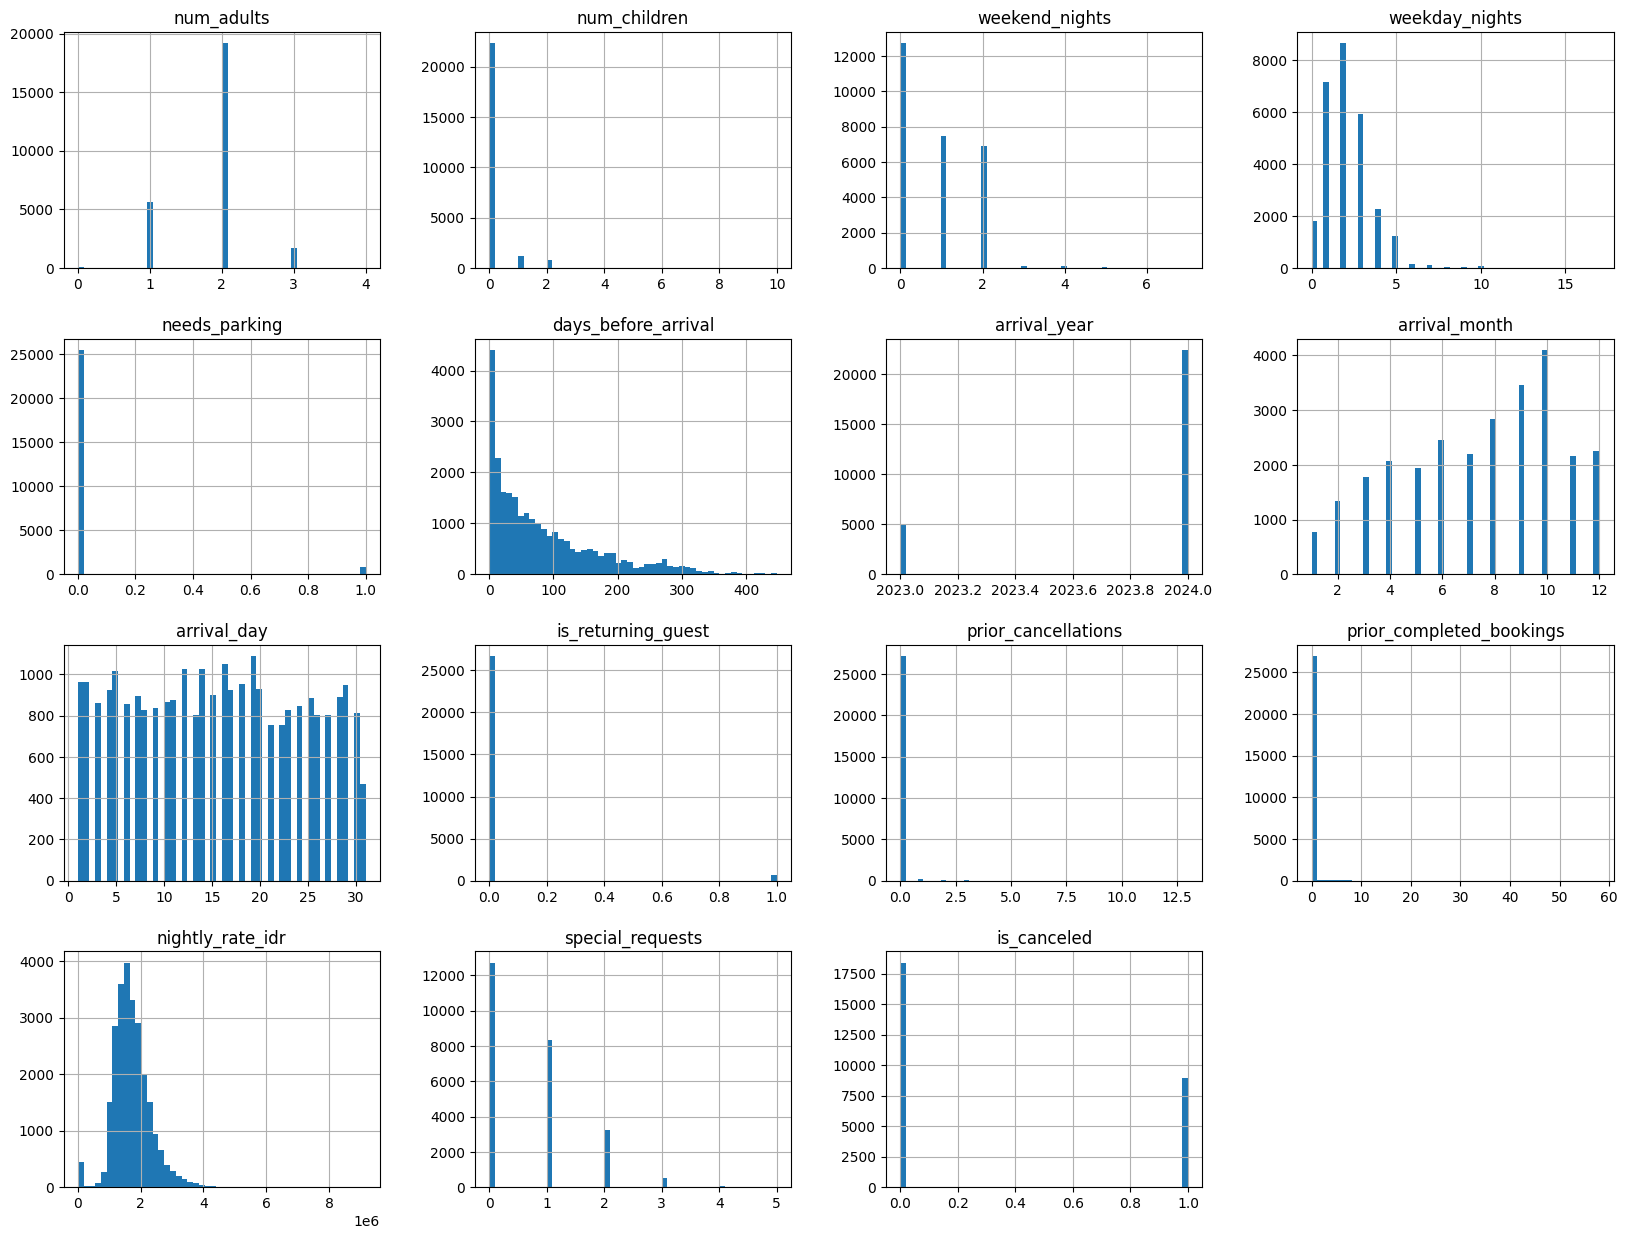

In [3]:
train_df.hist(bins=50, figsize=(20, 15))
plt.show()


Standard Correlation Coefficient (Pearson's r)


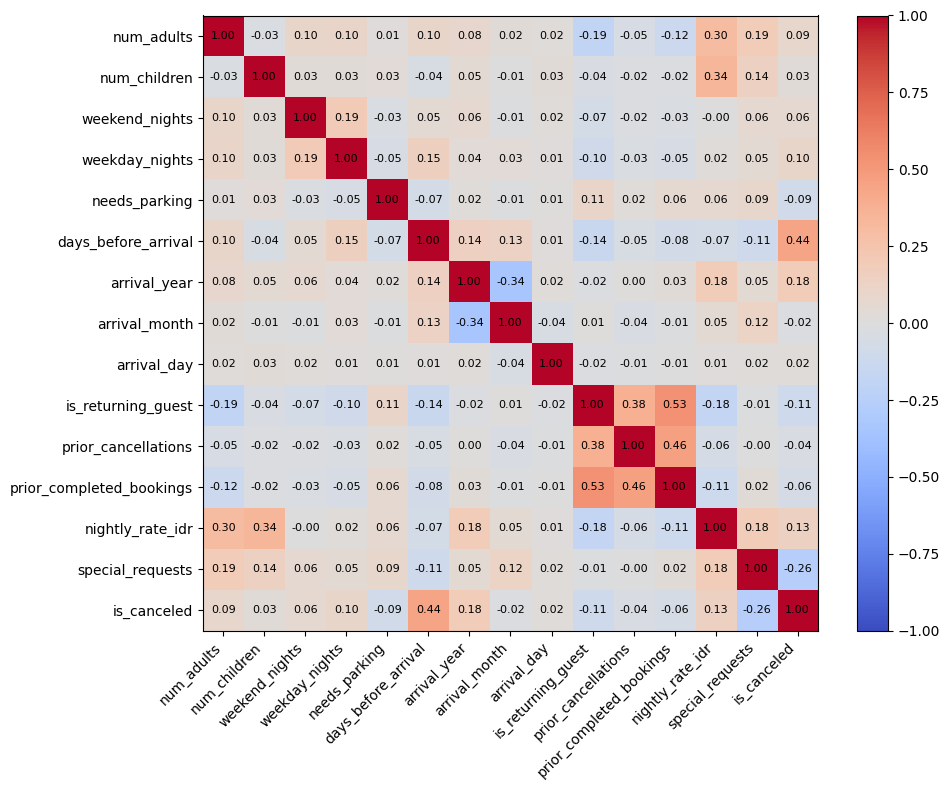

In [4]:
print("Standard Correlation Coefficient (Pearson's r)")
numeric_df = train_df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
plt.figure(figsize=(10, 8))
if sns is not None:
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
else:
    im = plt.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
    plt.colorbar(im)
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
    plt.yticks(range(len(corr.index)), corr.index)
    for i in range(len(corr.index)):
        for j in range(len(corr.columns)):
            plt.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
    plt.tight_layout()
plt.show()


## Data Preprocessing (Modular Pipeline)


In [5]:
prep = run_preprocessing(
    train_df,
    test_df,
    config=get_knn_preprocessing_config(random_state=RANDOM_STATE, verbose=True),
)


Train DF Missing Values
Total missing values = 13349. Missing percentage = 2.566685958310821%

Test DF Missing Values
Total missing values = 3281. Missing percentage = 2.6633222936554324%

Training dataset sebelum drop missing vals: 27373
Training dataset setelah drop missing vals: 16636

Sisa missing train_df values setelah cleaning = 0
Panjang train_df_cleaned setelah cleaning = 27373
Sisa missing test_df values setelah cleaning = 0
Panjang test_df_cleaned setelah cleaning = 6844

Nilai ganda training = 0

Jumlah nilai negatif pada data train: 0
Banyak pesanan tanpa orang dewasa (train) = 106
Banyak pesanan dengan jumlah malam 0 (train) = 64
Banyak tanggal invalid (train): 0
Panjang train_df_cleaned setelah hapus data invalid = 27203

Jumlah nilai negatif pada data test: 0
Banyak pesanan tanpa orang dewasa (test) = 22
Banyak pesanan dengan jumlah malam 0 (test) = 9
Banyak tanggal invalid (test): 0
Panjang test_df_cleaned setelah fill data invalid = 6844

Encoding selesai: train_encod

StandardScaler diterapkan pada 9 fitur numerik.

Data sebelum SMOTE: {0: 18268, 1: 8935}
Data setelah SMOTE: {1: 18268, 0: 18268}

Features score (sorted):
                                Feature        Score
0                   days_before_arrival  8181.976203
1                      special_requests  3390.638722
2                          arrival_year  1501.950908
3                      nightly_rate_idr   706.333498
4                    is_returning_guest   659.003064
5   booking_channel_Online Travel Agent   577.382680
6             booking_channel_Corporate   553.534144
7                         needs_parking   376.244815
8                            num_adults   348.102839
9                        weekday_nights   337.318398
10        booking_channel_Complimentary   289.500918
11             prior_completed_bookings   194.192925
12                       weekend_nights   134.870212
13                  prior_cancellations    69.925067
14                         num_children    38.969

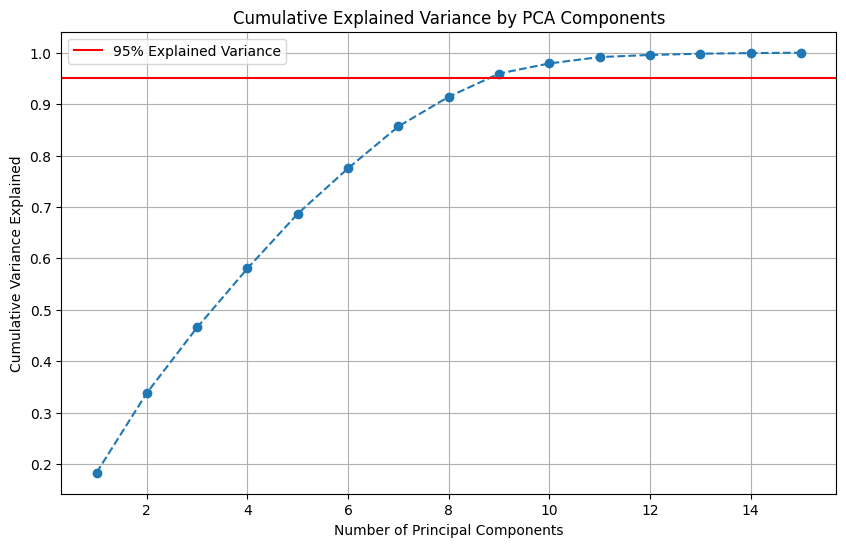

In [6]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(prep.cumulative_variance) + 1), prep.cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-', label='95% Explained Variance')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Explained')
plt.legend()
plt.grid(True)
plt.show()


## Modeling, Validation, and Model Comparison


In [7]:
verify_smote_order(prep.X_train_encoded, prep.X_train_balanced, verbose=True)
split_data = split_train_validation(
    prep.X_train,
    prep.y_train,
    is_orig=prep.is_orig,
    test_size=0.15,
    random_state=RANDOM_STATE,
    verbose=True,
)

evaluation_results = []


Asumsi urutan SMOTE benar: True
Ukuran data train: (31055, 9), Ukuran data validation: (5481, 9)
Validation: 4081 baris asli, 1400 baris sintetis (tidak dinilai)



### Model 1: K-Nearest Neighbors (KNN Scratch)


[KNN | k=5, metric=euclidean, p=2, weights=uniform, prob_thres=0.45] -> Mean Acc: 0.82869 | Mean Macro F1: 0.82868 (±0.00260)


[KNN | k=5, metric=euclidean, p=2, weights=inverted, prob_thres=0.45] -> Mean Acc: 0.83951 | Mean Macro F1: 0.83949 (±0.00322)


[KNN | k=3, metric=euclidean, p=2, weights=uniform, prob_thres=0.45] -> Mean Acc: 0.83246 | Mean Macro F1: 0.83245 (±0.00195)


[KNN | k=3, metric=euclidean, p=2, weights=inverted, prob_thres=0.45] -> Mean Acc: 0.83661 | Mean Macro F1: 0.83660 (±0.00248)


[KNN | k=5, metric=manhattan, p=1, weights=inverted, prob_thres=0.45] -> Mean Acc: 0.83967 | Mean Macro F1: 0.83965 (±0.00279)


,model,config,mean_accuracy,mean_macro_f1,std_macro_f1
0,KNN,"{'k': 5, 'metric': 'euclidean', 'p': 2, 'weigh...",0.828691,0.828675,0.002598
1,KNN,"{'k': 5, 'metric': 'euclidean', 'p': 2, 'weigh...",0.839511,0.839488,0.003219
2,KNN,"{'k': 3, 'metric': 'euclidean', 'p': 2, 'weigh...",0.832459,0.832453,0.001947
3,KNN,"{'k': 3, 'metric': 'euclidean', 'p': 2, 'weigh...",0.836612,0.836598,0.002479
4,KNN,"{'k': 5, 'metric': 'manhattan', 'p': 1, 'weigh...",0.839672,0.839647,0.002793



=== Evaluation: KNN ===
Accuracy (original val): 0.81892 | Macro F1: 0.79476
              precision    recall  f1-score   support

           0       0.87      0.87      0.87      2741
           1       0.72      0.72      0.72      1340

    accuracy                           0.82      4081
   macro avg       0.79      0.79      0.79      4081
weighted avg       0.82      0.82      0.82      4081



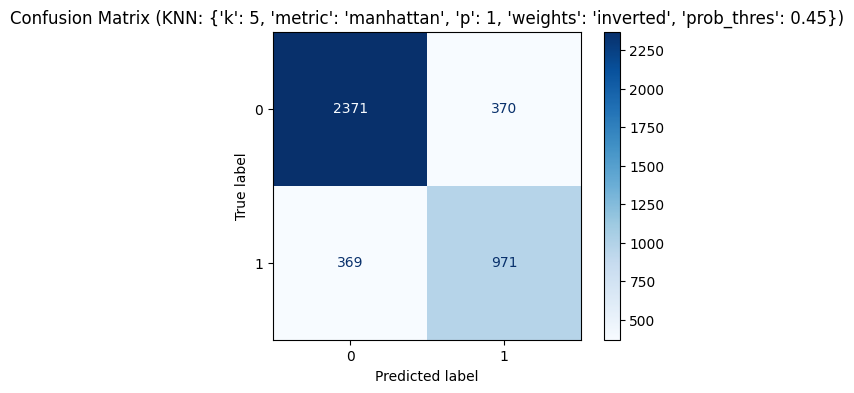

In [8]:
best_knn_config, knn_cv_df = cross_validate_configs(
    KNN,
    DEFAULT_KNN_CONFIGS,
    split_data.X_tr,
    split_data.y_tr,
    k_folds=5,
    random_state=RANDOM_STATE,
    model_name="KNN",
    verbose=True,
)
display(knn_cv_df)

knn_model_cfg = {k: v for k, v in best_knn_config.items() if k != "prob_thres"}
knn_result = train_and_evaluate(
    KNN(**knn_model_cfg),
    split_data,
    model_name="KNN",
    config=best_knn_config,
    X_test=prep.X_test,
    fit_orig_only=True,
    plot_cm=True,
)
evaluation_results.append(knn_result)


### Model 2: Naive Bayes (Weighted NB Scratch)

Naive Bayes tidak memakai pipeline scaling/SMOTE/PCA karena ketiganya merusak asumsi independensi dan distribusi fitur NB. Fitur dibuat dengan `prepare_nb_features`, lalu di dalam `WideNaiveBayes` dilakukan diskritisasi MDL, fitur gabungan, dan pembobotan per fitur. Detail eksperimen ada di `notebooks/naive_bayes_experiment.ipynb`.

Submisi NB yang sesuai spesifikasi adalah `output/submission_wnb.csv` (public score 0.85167) yang dibuat di `notebooks/naive_bayes_experiment.ipynb`.


Ukuran data train: (23267, 34), Ukuran data validation: (4106, 34)
Validation: 4106 baris asli, 0 baris sintetis (tidak dinilai)



[Naive Bayes | alpha=0.3, l2=10.0] -> Mean Acc: 0.85512 | Mean Macro F1: 0.83310 (±0.00340)


[Naive Bayes | alpha=0.3, l2=30.0] -> Mean Acc: 0.85697 | Mean Macro F1: 0.83517 (±0.00434)


,model,config,mean_accuracy,mean_macro_f1,std_macro_f1
0,Naive Bayes,"{'alpha': 0.3, 'l2': 10.0}",0.855117,0.833105,0.003402
1,Naive Bayes,"{'alpha': 0.3, 'l2': 30.0}",0.856965,0.835167,0.004344



=== Evaluation: Naive Bayes ===
Accuracy (original val): 0.86240 | Macro F1: 0.84169
              precision    recall  f1-score   support

           0       0.89      0.91      0.90      2761
           1       0.81      0.76      0.78      1345

    accuracy                           0.86      4106
   macro avg       0.85      0.84      0.84      4106
weighted avg       0.86      0.86      0.86      4106



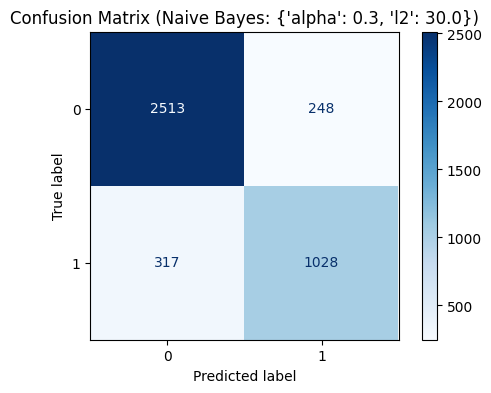

In [9]:
nb_split = split_train_validation(
    prepare_nb_features(train_df, extra=True, flags=True).values,
    train_df['is_canceled'].values,
    test_size=0.15,
    random_state=RANDOM_STATE,
    verbose=True,
)
X_test_nb = prepare_nb_features(test_df, extra=True, flags=True).values

best_nb_config, nb_cv_df = cross_validate_configs(
    WideNaiveBayes,
    DEFAULT_NB_CONFIGS,
    nb_split.X_tr,
    nb_split.y_tr,
    k_folds=5,
    random_state=RANDOM_STATE,
    model_name="Naive Bayes",
    verbose=True,
)
display(nb_cv_df)

nb_result = train_and_evaluate(
    WideNaiveBayes(**best_nb_config),
    nb_split,
    model_name="Naive Bayes",
    config=best_nb_config,
    X_test=X_test_nb,
    plot_cm=True,
)
evaluation_results.append(nb_result)


### Model 3: Decision Tree Learning (C4.5 Scratch)

Fitur DTL dibuat dengan prepare_dtl_features. Kolom kategori tetap diperlakukan
sebagai kategori oleh pohon. Eksperimen serta pembanding scikit-learn ada
di notebooks/dtl_experiment.ipynb.


Ukuran data train: (23267, 35), Ukuran data validation: (4106, 35)
Validation: 4106 baris asli, 0 baris sintetis (tidak dinilai)



[DTL | max_depth=16, min_branch_weight=7, threshold=0.48, categorical_features=[9, 10, 11, 12, 13, 14, 17]] -> Mean Acc: 0.85572 | Mean Macro F1: 0.83515 (±0.00581)


,model,config,mean_accuracy,mean_macro_f1,std_macro_f1
0,DTL,"{'max_depth': 16, 'min_branch_weight': 7, 'thr...",0.855719,0.835147,0.005809



=== Evaluation: DTL ===
Accuracy (original val): 0.85704 | Macro F1: 0.83765
              precision    recall  f1-score   support

           0       0.89      0.89      0.89      2761
           1       0.78      0.78      0.78      1345

    accuracy                           0.86      4106
   macro avg       0.84      0.84      0.84      4106
weighted avg       0.86      0.86      0.86      4106



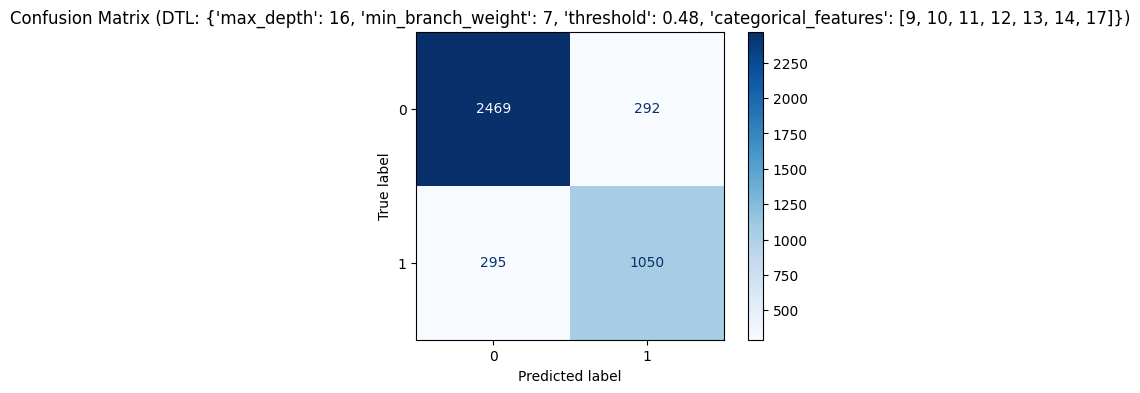

In [10]:
X_dtl = prepare_dtl_features(train_df.drop_duplicates())
X_dtl_test = prepare_dtl_features(test_df)
dtl_categorical_indices = [
    X_dtl.columns.get_loc(column) for column in DTL_CATEGORICAL_COLUMNS
]
dtl_configs = [
    dict(config, categorical_features=dtl_categorical_indices)
    for config in DEFAULT_DTL_CONFIGS
]
dtl_split = split_train_validation(
    X_dtl.values,
    train_df.drop_duplicates()["is_canceled"].values,
    test_size=0.15,
    random_state=RANDOM_STATE,
)

best_dtl_config, dtl_cv_df = cross_validate_configs(
    C45DecisionTree,
    dtl_configs,
    dtl_split.X_tr,
    dtl_split.y_tr,
    k_folds=5,
    random_state=RANDOM_STATE,
    model_name="DTL",
)
display(dtl_cv_df)

dtl_result = train_and_evaluate(
    C45DecisionTree(**best_dtl_config),
    dtl_split,
    model_name="DTL",
    config=best_dtl_config,
    X_test=X_dtl_test.values,
)
evaluation_results.append(dtl_result)


### Model 4: Logistic Regression (Scratch)

Implementasi LogisticRegression di src/models/logistic_regression.py mewarisi BaseModel dengan pilihan optimasi Stochastic Gradient Ascent (SGA) dan Adam serta regularisasi L1, L2, dan Elastic Net. Perbandingan dengan scikit-learn dan detail eksperimen tersedia di notebooks/logistic_regression_experiment.ipynb.

[Logistic Regression | optimizer=sga, penalty=None, learning_rate=0.01, reg_lambda=0.0, l1_ratio=0.5, max_iter=20, random_state=824] -> Mean Acc: 0.75147 | Mean Macro F1: 0.75121 (±0.00402)


[Logistic Regression | optimizer=sga, penalty=l1, learning_rate=0.01, reg_lambda=0.0001, l1_ratio=0.5, max_iter=20, random_state=824] -> Mean Acc: 0.75083 | Mean Macro F1: 0.75056 (±0.00445)


[Logistic Regression | optimizer=sga, penalty=l2, learning_rate=0.01, reg_lambda=0.0001, l1_ratio=0.5, max_iter=20, random_state=824] -> Mean Acc: 0.74999 | Mean Macro F1: 0.74971 (±0.00433)


[Logistic Regression | optimizer=sga, penalty=elasticnet, learning_rate=0.01, reg_lambda=0.0001, l1_ratio=0.5, max_iter=20, random_state=824] -> Mean Acc: 0.74977 | Mean Macro F1: 0.74948 (±0.00388)


[Logistic Regression | optimizer=adam, penalty=l2, learning_rate=0.02, batch_size=256, reg_lambda=0.0001, l1_ratio=0.5, max_iter=30, random_state=824] -> Mean Acc: 0.75064 | Mean Macro F1: 0.75051 (±0.00496)


[Logistic Regression | optimizer=adam, penalty=elasticnet, learning_rate=0.02, batch_size=256, reg_lambda=0.0001, l1_ratio=0.5, max_iter=30, random_state=824] -> Mean Acc: 0.75093 | Mean Macro F1: 0.75079 (±0.00502)


,model,config,mean_accuracy,mean_macro_f1,std_macro_f1
0,Logistic Regression,"{'optimizer': 'sga', 'penalty': None, 'learnin...",0.751473,0.751211,0.004018
1,Logistic Regression,"{'optimizer': 'sga', 'penalty': 'l1', 'learnin...",0.750829,0.750558,0.004454
2,Logistic Regression,"{'optimizer': 'sga', 'penalty': 'l2', 'learnin...",0.749992,0.749708,0.004329
3,Logistic Regression,"{'optimizer': 'sga', 'penalty': 'elasticnet', ...",0.749767,0.749485,0.003879
4,Logistic Regression,"{'optimizer': 'adam', 'penalty': 'l2', 'learni...",0.750636,0.750506,0.004957
5,Logistic Regression,"{'optimizer': 'adam', 'penalty': 'elasticnet',...",0.750926,0.750794,0.005021



=== Evaluation: Logistic Regression ===
Accuracy (original val): 0.77922 | Macro F1: 0.72441
              precision    recall  f1-score   support

           0       0.79      0.91      0.85      2741
           1       0.74      0.51      0.60      1340

    accuracy                           0.78      4081
   macro avg       0.76      0.71      0.72      4081
weighted avg       0.77      0.78      0.77      4081



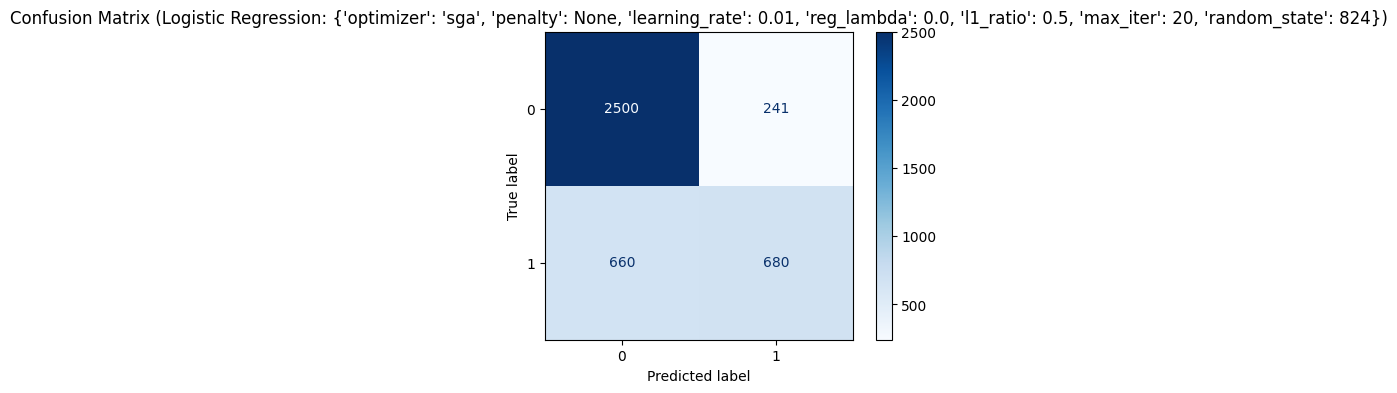

In [11]:
best_logreg_config, logreg_cv_df = cross_validate_configs(
    LogisticRegression,
    DEFAULT_LOGREG_CONFIGS,
    split_data.X_tr,
    split_data.y_tr,
    k_folds=5,
    random_state=RANDOM_STATE,
    model_name="Logistic Regression",
    verbose=True,
)
display(logreg_cv_df)

logreg_model_cfg = {k: v for k, v in best_logreg_config.items() if k != "prob_thres"}
logreg_result = train_and_evaluate(
    LogisticRegression(**logreg_model_cfg),
    split_data,
    model_name="Logistic Regression",
    config=best_logreg_config,
    X_test=prep.X_test,
    fit_orig_only=True,
    plot_cm=True,
)
evaluation_results.append(logreg_result)

### Model 5: Support Vector Machine (SVM Scratch)

Implementasi `SVM` di `src/svm/` menggunakan solver Sequential Minimal Optimization (SMO) orde kedua dengan dukungan kernel Linear, Polynomial, dan Gaussian (RBF) serta rekayasa fitur (`load_engineered_data`). Eksperimen perbandingan ketiga kernel terhadap `scikit-learn` dan visualisasi bidang pemisah 2D tersedia di `notebooks/svm_experiment.ipynb`.

In [12]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score

svm_data = load_engineered_data(DATA_DIR, random_state=RANDOM_STATE, test_size=0.15)
svm_sub_idx = stratified_subset_indices(svm_data.y_tr, svm_data.orig_tr, max_samples=15000, random_state=RANDOM_STATE)
X_svm_sub, y_svm_sub = svm_data.X_tr[svm_sub_idx], svm_data.y_tr[svm_sub_idx]
svm_gamma = 1.25 / (X_svm_sub.shape[1] * X_svm_sub.var())
svm_config = {'C': 20.0, 'kernel': 'rbf', 'gamma': round(float(svm_gamma), 6), 'threshold': 0.0695}

svm_val_model = SVM(
    C=20.0, kernel='rbf', gamma=svm_gamma, tol=1e-3, max_iter=60000,
    random_state=RANDOM_STATE, cache_size_mb=2048.0,
).fit(X_svm_sub, y_svm_sub)
svm_val_preds = (svm_val_model.decision_function(svm_data.X_val) > 0.0695).astype(int)
svm_acc = float(accuracy_score(svm_data.y_val, svm_val_preds))
svm_f1 = float(f1_score(svm_data.y_val, svm_val_preds, average='macro'))
print(f'\n=== Evaluation: SVM ===')
print(f'Accuracy (original val): {svm_acc:.5f} | Macro F1: {svm_f1:.5f}')
print(classification_report(svm_data.y_val, svm_val_preds))

evaluation_results.append({
    'model_name': 'SVM',
    'model': svm_val_model,
    'config': svm_config,
    'accuracy': svm_acc,
    'macro_f1': svm_f1,
    'report': classification_report(svm_data.y_val, svm_val_preds),
    'confusion_matrix': confusion_matrix(svm_data.y_val, svm_val_preds),
    'val_preds': svm_val_preds,
    'X_test': svm_data.X_test,
})



=== Evaluation: SVM ===
Accuracy (original val): 0.86324 | Macro F1: 0.83911
              precision    recall  f1-score   support

           0       0.87      0.93      0.90      2740
           1       0.84      0.72      0.78      1340

    accuracy                           0.86      4080
   macro avg       0.86      0.83      0.84      4080
weighted avg       0.86      0.86      0.86      4080



### Model Comparison


In [13]:
comparison_df = compare_models(evaluation_results)
display(comparison_df)

best_result = max(evaluation_results, key=lambda item: item["macro_f1"])
print(f"Best model: {best_result['model_name']} (Macro F1 = {best_result['macro_f1']:.5f})")


,Model,Accuracy,Macro F1,Config
0,Naive Bayes,0.862396,0.841689,"{'alpha': 0.3, 'l2': 30.0}"
1,SVM,0.863235,0.839107,"{'C': 20.0, 'kernel': 'rbf', 'gamma': 0.02185,..."
2,DTL,0.857038,0.837648,"{'max_depth': 16, 'min_branch_weight': 7, 'thr..."
3,KNN,0.818917,0.794764,"{'k': 5, 'metric': 'manhattan', 'p': 1, 'weigh..."
4,Logistic Regression,0.779221,0.724409,"{'optimizer': 'sga', 'penalty': None, 'learnin..."


Best model: Naive Bayes (Macro F1 = 0.84169)


## Submission


In [14]:
OUTPUT_DIR = Path('output') if Path('output').is_dir() else Path('../output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Verifikasi save/load dan reproduksi submisi terbaik Kaggle (SVM RBF - public score 0.86363)
X_svm_full, y_svm_full, X_svm_test_full, svm_test_ids, _ = load_engineered_final(DATA_DIR, random_state=RANDOM_STATE)
svm_best_ckpt = joblib.load(OUTPUT_DIR / 'checkpoints_best' / 'svm_scratch_0.86363.pkl')
assert check_serialization(svm_best_ckpt, X_svm_test_full[:256]), 'SVM round-trip check failed!'
svm_final_csv = save_submission(
    svm_best_ckpt,
    X_svm_test_full,
    svm_test_ids,
    output_path=OUTPUT_DIR / 'submission_svm_final.csv',
    sample_submission_path=DATA_DIR / 'sample_submission.csv',
    threshold=0.0695,
)
submission = pd.read_csv(svm_final_csv)
print(f"Submisi terbaik Kaggle berhasil direproduksi ke '{svm_final_csv}' (Distribusi: {submission['is_canceled'].value_counts().to_dict()})")
display(submission.head())


Submisi terbaik Kaggle berhasil direproduksi ke 'output/submission_svm_final.csv' (Distribusi: {0: 4823, 1: 2021})


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,1
4,621586b6,0
